# Live training demo: a CNN learning from Nonspeech7k

Shows the full deep-learning loop on a **small subset of the training partition** (no test clips): initialisation, forward pass, loss, backpropagation, optimizer step, parameter updates, validation. The real experiments (`train_cnn.py`, `ast_finetune.py`) use the same code at full scale.

In [1]:
import os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
REPO = Path.cwd().parent if Path.cwd().name == "professor_demo" else Path.cwd()
sys.path.insert(0, str(REPO))
# data and results live next to the repository; override with environment variables if moved
DATA = Path(os.environ.get("NS7K_DATA", REPO.parent / "data"))
RESULTS = Path(os.environ.get("NS7K_RESULTS", REPO.parent / "results" / "v3"))
from common import index_audio
from features import load_mono
from dl_data import CLASSES
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(), "| CPU threads:", torch.get_num_threads())
audio = index_audio(DATA / "audio")
splits = pd.read_csv(RESULTS / "dl" / "splits.csv")
print(len(audio), "audio files indexed;", len(splits), "clips in the split manifest")

torch 2.15.0+cpu | CUDA available: False | CPU threads: 4
7014 audio files indexed; 7014 clips in the split manifest


In [2]:
import torch.nn.functional as F
from train_cnn import LogMelCNN, augment
from dl_metrics import metrics
torch.manual_seed(0)
M = np.load(RESULTS / "dl" / "logmel.npy", mmap_mode="r")
tr = splits.index[splits.source_disjoint == "train"].values
va = splits.index[splits.source_disjoint == "val"].values
rng = np.random.default_rng(0)
tr_s = np.sort(np.concatenate([rng.choice(tr[splits.y.values[tr] == c], 40, replace=False) for c in range(7)]))
va_s = np.sort(np.concatenate([rng.choice(va[splits.y.values[va] == c], 15, replace=False) for c in range(7)]))
mu = np.asarray(M[tr_s], np.float32).mean((0, 2), keepdims=True)[0]; sd = np.asarray(M[tr_s], np.float32).std((0, 2), keepdims=True)[0] + 1e-5
Xtr = torch.from_numpy((np.asarray(M[tr_s], np.float32) - mu) / sd); ytr = torch.tensor(splits.y.values[tr_s])
Xva = torch.from_numpy((np.asarray(M[va_s], np.float32) - mu) / sd); yva = torch.tensor(splits.y.values[va_s])
print("train subset", Xtr.shape, "| val subset", Xva.shape, "| test clips used: 0")

train subset torch.Size([280, 64, 400]) | val subset torch.Size([105, 64, 400]) | test clips used: 0


## 1. Initialise the network

In [3]:
model = LogMelCNN(7, 16)
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

LogMelCNN(
  (features): Sequential(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
   

## 2. One step by hand: forward, loss, backward, optimizer step

In [4]:
xb, yb = Xtr[:16], ytr[:16]
w0 = model.head.weight.detach().clone(); c0 = model.features[0].net[0].weight.detach().clone()
logits = model(xb)                                  # forward propagation
loss = F.cross_entropy(logits, yb)                  # loss
opt.zero_grad(); loss.backward()                    # backpropagation
print("logits shape", tuple(logits.shape), "| loss", round(loss.item(), 4))
print("gradient norm, first conv:", model.features[0].net[0].weight.grad.norm().item())
print("gradient norm, head      :", model.head.weight.grad.norm().item())
opt.step()                                          # optimizer step
print("first-conv weights changed by", (model.features[0].net[0].weight - c0).norm().item())
print("head weights changed by      ", (model.head.weight - w0).norm().item())

logits shape (16, 7) | loss 1.5443
gradient norm, first conv: 2.4066059589385986
gradient norm, head      : 18.372859954833984
first-conv weights changed by 0.023998241871595383
head weights changed by       0.0846637636423111


## 3. Short training run with validation after every epoch

epoch 1 train_loss 1.877 val_loss 1.774 val_acc 0.381 val_macroF1 0.302 (12s)


epoch 2 train_loss 1.558 val_loss 1.644 val_acc 0.371 val_macroF1 0.295 (27s)


epoch 3 train_loss 1.291 val_loss 1.772 val_acc 0.343 val_macroF1 0.302 (39s)


epoch 4 train_loss 1.085 val_loss 1.447 val_acc 0.467 val_macroF1 0.427 (50s)


epoch 5 train_loss 1.192 val_loss 1.505 val_acc 0.486 val_macroF1 0.441 (62s)


epoch 6 train_loss 1.012 val_loss 1.379 val_acc 0.533 val_macroF1 0.485 (73s)


epoch 7 train_loss 1.075 val_loss 1.599 val_acc 0.495 val_macroF1 0.402 (85s)


epoch 8 train_loss 0.976 val_loss 1.498 val_acc 0.552 val_macroF1 0.511 (97s)


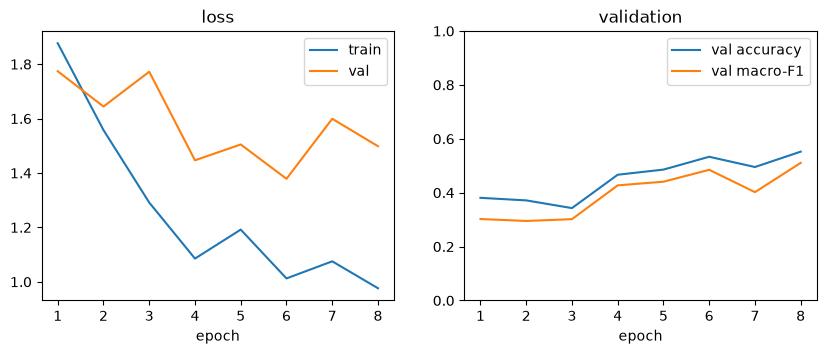

In [5]:
hist = []; gen = torch.Generator().manual_seed(0)
t0 = time.time()
for ep in range(1, 9):
    model.train(); perm = torch.randperm(len(Xtr), generator=gen); tot = 0
    for i in range(0, len(perm), 16):
        b = perm[i:i+16]
        loss = F.cross_entropy(model(augment(Xtr[b], gen)), ytr[b])
        opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
    model.eval()
    with torch.no_grad():
        lv = model(Xva); vl = F.cross_entropy(lv, yva).item()
    m = metrics(yva.numpy(), lv.argmax(1).numpy(), 7)
    hist.append(dict(epoch=ep, train_loss=tot/len(Xtr), val_loss=vl, val_acc=m["accuracy"], val_macro_f1=m["macro_f1"]))
    print(f"epoch {ep} train_loss {tot/len(Xtr):.3f} val_loss {vl:.3f} val_acc {m['accuracy']:.3f} val_macroF1 {m['macro_f1']:.3f} ({time.time()-t0:.0f}s)")
h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set(title="loss", xlabel="epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.val_acc, label="val accuracy"); ax[1].plot(h.epoch, h.val_macro_f1, label="val macro-F1"); ax[1].set(title="validation", xlabel="epoch", ylim=(0, 1)); ax[1].legend()
plt.show()

A 280-clip, 8-epoch run is only a demonstration of the training loop; the full experiment's learning curves are in `results/v3/report/G1_G2_learning_curves_*.png`.

## 4. Evidence that the pretrained AST was actually fine-tuned
Gradient norms on pretrained transformer weights during training, and how far those weights moved.

In [6]:
run = RESULTS / "runs" / "ast_ft_source_disjoint_standard_s0"
print(open(run / "train.log").read().splitlines()[-1])
display(pd.read_csv(run / "grad_norms.csv").T.head(12))
drift = pd.read_csv(run / "weight_drift.csv", index_col=0)
drift.sort_values("relative_change", ascending=False).head(10)

TEST: acc 0.804 macroF1 0.785 bal_acc 0.837; max relative change of pretrained weights 0.0214


,0,1,2,3
epoch,1.000000,2.000000,3.000000,4.000000
ast_layer_11.attention.q_proj.weight,0.784046,0.207267,0.171323,0.120022
ast_layer_11.mlp.fc1.weight,2.901779,0.815112,0.899118,0.594886
ast_layer_11.mlp.fc2.weight,3.328389,0.907732,0.950686,0.655757


,relative_change
ast_layer_11.attention.q_proj.weight,0.021429
ast_layer_11.attention.k_proj.weight,0.021366
ast_layer_11.mlp.fc1.weight,0.019324
ast_layer_11.mlp.fc2.weight,0.013964
ast_layer_11.attention.v_proj.weight,0.010673
ast_layer_11.attention.o_proj.weight,0.009992
ast_layer_11.attention.v_proj.bias,0.002125
ast_layer_11.attention.k_proj.bias,0.002001
ast_layer_11.layernorm_after.bias,0.001384
ast_layer_11.layernorm_before.bias,0.000733
